# Inventory Replenishment Agent
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/2hv2yjnnhd-create/inventory-replenishment-agent/blob/main/replenishment_agent.ipynb)

**3 SKUs, 90 days, one decision per SKU per day: ORDER or WAIT.**

Every simulated day the agent looks at stock on hand, stock already on order, an EWMA demand
forecast and a safety stock buffer. It projects inventory over the lead time plus review period,
decides to ORDER or WAIT, and writes down why. At the end we compare it with a fixed reorder rule
on the same data and costs, then test how service level and alpha change the results.

Structure follows the course starter code (`supplychain.py` and `InventoryReplenishmentAgent.ipynb`):
**Obs** (what the agent sees) -> **Memory** (what it remembers) -> **tools** (forecast, safety stock)
-> **decide** -> **act** (place the order).

**How to run:** Runtime > Run all. If `sales.csv`, `inventory.csv` and `params.csv` are not in the
`data/` folder, Step 1 creates them (fixed seed, same numbers every time). Results are saved to `outputs/`.

## Step 0: Settings you can change
Per-SKU costs, lead time, MOQ and service level live in `params.csv`.
Everything else the agent uses is here.

In [1]:
import math
import os
from dataclasses import dataclass, field

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

# ---- Agent settings ----
ALPHA = 0.3                  # EWMA smoothing: higher = forecast reacts faster to recent sales
REVIEW_PERIOD_DAYS = 1       # agent reviews every SKU every day
MIN_ERRORS_FOR_SIGMA = 7     # need 7 forecast errors before trusting them for safety stock
ERROR_WINDOW = 28            # use the most recent 28 forecast errors to measure uncertainty
CYCLE_COVER_DAYS = 7         # when ordering, buy about a week of demand beyond the reorder point
CAP_DAYS_OF_DEMAND = 30      # inventory cap: never hold more than ~30 days of forecast demand
FIXED_ORDER_COST = 0.0       # $ per purchase order (assignment allows $0)

# Optional overrides. None = use the value from params.csv for each SKU.
SERVICE_LEVEL_OVERRIDE = None    # e.g. 0.99 to test a higher target for every SKU
LEAD_TIME_OVERRIDE = None        # e.g. 10 to test a slower supplier for every SKU

# Planner's starting guess for daily demand (last quarter's average).
# Used only to start the forecast on day 1. The baseline rule is built from the same numbers.
INITIAL_FORECAST = {"BOTTLE01": 20.0, "FAN01": 8.0, "CHAIR01": 1.5}

# ---- Baseline rule (fixed reorder point, fixed order quantity) ----
BASELINE_ORDER_DAYS = 14     # baseline orders two weeks of demand at a time (at least the MOQ)

PRINT_DAILY_LOG = True       # print the full agent log (every SKU, every day)

# ---- Folders ----
DATA_DIR = "data"            # input CSVs
OUTPUT_DIR = "outputs"       # logs, result tables and the chart
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

## Step 1: Create the three CSVs (only if they are missing)
90 days (2026-07-01 to 2026-09-28), 3 SKUs with different demand patterns:

| SKU | Product | Pattern |
|---|---|---|
| BOTTLE01 | water bottle | steady seller, about 20/day, weekends about 30% higher |
| FAN01 | desk fan | about 8/day, then a two-week heat wave (Aug 3 to 16) at about 3x |
| CHAIR01 | office chair | slow mover, about 1.5/day, supplier MOQ of 50 |

CHAIR01 only has a row on days it sold something, like a real point-of-sale export.

In [2]:
DATA_SEED = 42


def daily_mean(sku, date):
    """Average demand for one SKU on one date, before random noise."""
    if sku == "BOTTLE01":
        return 20.0 * (1.3 if date.day_of_week >= 5 else 1.0)
    if sku == "FAN01":
        heat_wave = pd.Timestamp("2026-08-03") <= date <= pd.Timestamp("2026-08-16")
        return 24.0 if heat_wave else 8.0
    if sku == "CHAIR01":
        return 1.5
    raise ValueError(sku)


def make_csvs():
    rng = np.random.default_rng(DATA_SEED)
    dates = pd.date_range("2026-07-01", periods=90, freq="D")

    rows = []
    for sku in ["BOTTLE01", "FAN01", "CHAIR01"]:
        for date in dates:
            qty = int(rng.poisson(daily_mean(sku, date)))
            if sku == "CHAIR01" and qty == 0:
                continue                                 # no sale, no row
            rows.append({"date": date.strftime("%Y-%m-%d"), "sku": sku, "qty_sold": qty})
    pd.DataFrame(rows).to_csv(f"{DATA_DIR}/sales.csv", index=False)

    pd.DataFrame([
        {"sku": "BOTTLE01", "opening_stock": 150},
        {"sku": "FAN01", "opening_stock": 80},
        {"sku": "CHAIR01", "opening_stock": 25},
    ]).to_csv(f"{DATA_DIR}/inventory.csv", index=False)

    # unit_cost and stockout_cost are $ per unit, holding_cost_per_day is $ per unit per day
    pd.DataFrame([
        {"sku": "BOTTLE01", "unit_cost": 12, "holding_cost_per_day": 0.03, "stockout_cost": 6,
         "lead_time_days": 5, "min_order_qty": 60, "service_level": 0.95},
        {"sku": "FAN01", "unit_cost": 30, "holding_cost_per_day": 0.08, "stockout_cost": 15,
         "lead_time_days": 7, "min_order_qty": 40, "service_level": 0.95},
        {"sku": "CHAIR01", "unit_cost": 85, "holding_cost_per_day": 0.25, "stockout_cost": 40,
         "lead_time_days": 10, "min_order_qty": 50, "service_level": 0.90},
    ]).to_csv(f"{DATA_DIR}/params.csv", index=False)


if all(os.path.exists(f"{DATA_DIR}/{f}") for f in ["sales.csv", "inventory.csv", "params.csv"]):
    print(f"Using existing sales.csv, inventory.csv, params.csv in {DATA_DIR}/")
else:
    make_csvs()
    print(f"Created sales.csv, inventory.csv, params.csv in {DATA_DIR}/")

Using existing sales.csv, inventory.csv, params.csv in data/


## Step 2: Load, validate and aggregate the data
**Assumptions**
- More than one row for the same SKU and date: add them together.
- A date with no sales row: **zero demand** (we assume the file records every sale).
- Negative or missing `qty_sold`: treated as a data error, set to 0, and a warning is printed.
- A missing or invalid value in `params.csv` or `inventory.csv`: stop with an error. We don't guess costs.
- Unmet demand is **lost**, not backordered (the customer buys somewhere else).

In [3]:
SALES_COLUMNS = ["date", "sku", "qty_sold"]
INVENTORY_COLUMNS = ["sku", "opening_stock"]
PARAMS_COLUMNS = ["sku", "unit_cost", "holding_cost_per_day", "stockout_cost",
                  "lead_time_days", "min_order_qty", "service_level"]


def load_and_validate(sales_path=f"{DATA_DIR}/sales.csv", inventory_path=f"{DATA_DIR}/inventory.csv",
                      params_path=f"{DATA_DIR}/params.csv"):
    """Load the 3 CSVs, check them, and return daily demand per SKU plus opening stock and policy."""
    sales = pd.read_csv(sales_path)
    inventory = pd.read_csv(inventory_path)
    params = pd.read_csv(params_path)

    # 1. Column names must match the assignment exactly
    assert list(sales.columns) == SALES_COLUMNS, f"sales.csv columns: {list(sales.columns)}"
    assert list(inventory.columns) == INVENTORY_COLUMNS, f"inventory.csv columns: {list(inventory.columns)}"
    assert list(params.columns) == PARAMS_COLUMNS, f"params.csv columns: {list(params.columns)}"

    # 2. Sales: parse dates, fix missing or negative quantities
    sales["date"] = pd.to_datetime(sales["date"])
    if sales["qty_sold"].isna().any():
        print(f"WARNING: {sales['qty_sold'].isna().sum()} missing qty_sold values set to 0")
        sales["qty_sold"] = sales["qty_sold"].fillna(0)
    if (sales["qty_sold"] < 0).any():
        print(f"WARNING: {(sales['qty_sold'] < 0).sum()} negative qty_sold values set to 0")
        sales.loc[sales["qty_sold"] < 0, "qty_sold"] = 0

    # 3. Inventory and params: no missing values, sensible ranges
    if inventory.isna().any().any() or params.isna().any().any():
        raise ValueError("inventory.csv or params.csv has a missing value. Fix the file before running.")
    if (inventory["opening_stock"] < 0).any():
        raise ValueError("opening_stock can't be negative")
    if not params["service_level"].between(0.5, 0.999).all():
        raise ValueError("service_level must be between 0.5 and 0.999")
    if (params["lead_time_days"] < 1).any() or (params["min_order_qty"] < 1).any():
        raise ValueError("lead_time_days and min_order_qty must be at least 1")

    # 4. Aggregate: one number per SKU per day (adds up duplicate rows)
    duplicates = sales.duplicated(["date", "sku"]).sum()
    if duplicates:
        print(f"Note: {duplicates} duplicate date/SKU rows were added together")
    daily = sales.groupby(["date", "sku"], as_index=False)["qty_sold"].sum()

    # 5. Fill missing dates with zero demand (wide table: rows = dates, columns = SKUs)
    all_dates = pd.date_range(daily["date"].min(), daily["date"].max(), freq="D")
    demand = (daily.pivot(index="date", columns="sku", values="qty_sold")
                   .reindex(all_dates))
    missing_days = demand.isna().sum()
    for sku, n in missing_days.items():
        if n:
            print(f"Note: {sku} has {n} dates with no sales row, treated as zero demand")
    demand = demand.fillna(0).astype(int)
    demand.index.name = "date"

    # 6. Every SKU with sales must have opening stock and policy settings
    for sku in demand.columns:
        assert sku in set(inventory["sku"]), f"{sku} missing from inventory.csv"
        assert sku in set(params["sku"]), f"{sku} missing from params.csv"

    opening_stock = inventory.set_index("sku")["opening_stock"].astype(int).to_dict()
    policy = params.set_index("sku").to_dict(orient="index")
    return demand, opening_stock, policy


demand, opening_stock, policy = load_and_validate()
SKUS = list(INITIAL_FORECAST)          # fixed display order
assert set(SKUS) == set(demand.columns)

print(f"\nLoaded {len(demand)} days ({demand.index[0].date()} to {demand.index[-1].date()}) for {SKUS}")
print("Opening stock:", opening_stock)
print("\nPolicy settings from params.csv:")
print(pd.DataFrame(policy).T.loc[SKUS])
print("\nDaily demand summary:")
print(demand[SKUS].describe().round(1).loc[["mean", "std", "min", "max"]])

Note: CHAIR01 has 15 dates with no sales row, treated as zero demand

Loaded 90 days (2026-07-01 to 2026-09-28) for ['BOTTLE01', 'FAN01', 'CHAIR01']
Opening stock: {'BOTTLE01': 150, 'FAN01': 80, 'CHAIR01': 25}

Policy settings from params.csv:
          unit_cost  holding_cost_per_day  stockout_cost  lead_time_days  min_order_qty  service_level
BOTTLE01       12.0                  0.03            6.0             5.0           60.0           0.95
FAN01          30.0                  0.08           15.0             7.0           40.0           0.95
CHAIR01        85.0                  0.25           40.0            10.0           50.0           0.90

Daily demand summary:
sku   BOTTLE01  FAN01  CHAIR01
mean      21.5   10.1      1.7
std        5.1    6.3      1.3
min       11.0    2.0      0.0
max       35.0   30.0      7.0


## Step 3: Agent tools: forecast and safety stock
**EWMA forecast:** `tomorrow's forecast = ALPHA x today's sales + (1 - ALPHA) x today's forecast`
- Day 1 starts from the planner's guess in `INITIAL_FORECAST`.
- The update runs at the **end** of each day, after that day's sales are known, so the forecast used for
  a decision on day *t* only contains sales from days before *t*. (Step 9 checks this with an assert.)

**Safety stock:** `z x sigma x sqrt(lead time + review period)`
- **z** comes from the SKU's service level (95% gives z of about 1.645, 90% gives about 1.28).
- **sigma** is the standard deviation of the last 28 daily forecast errors (actual minus forecast).
- **sqrt(lead time + review period)**: the buffer has to cover every day until the *next* order could arrive,
  which is the lead time plus one review period, not just the lead time.
- **Not enough history yet?** Until there are 7 errors, we assume demand behaves like a Poisson process
  (sigma is about sqrt(forecast)). That gives a sensible buffer from day 1 instead of zero.

In [4]:
def tool_update_forecast(old_forecast, actual_demand, alpha):
    """EWMA update. Called at the END of the day, after that day's demand is known."""
    return alpha * actual_demand + (1 - alpha) * old_forecast


def tool_safety_stock(errors, forecast, service_level, lead_time, review_period=REVIEW_PERIOD_DAYS):
    """Return (safety stock, sigma, where sigma came from)."""
    z = norm.ppf(service_level)
    if len(errors) >= MIN_ERRORS_FOR_SIGMA:
        recent = np.array(errors[-ERROR_WINDOW:])
        sigma = float(np.std(recent, ddof=1))            # spread of signed forecast errors
        basis = f"std of last {len(recent)} forecast errors"
    else:
        sigma = math.sqrt(max(forecast, 1.0))            # Poisson fallback
        basis = "Poisson fallback (under 7 errors)"
    return z * sigma * math.sqrt(lead_time + review_period), sigma, basis


# Quick look: what the tools give for each SKU on day 1
for sku in SKUS:
    p = policy[sku]
    ss, sigma, basis = tool_safety_stock([], INITIAL_FORECAST[sku], p["service_level"], int(p["lead_time_days"]))
    print(f"{sku}: day-1 forecast {INITIAL_FORECAST[sku]}/day, sigma {sigma:.2f} ({basis}), "
          f"safety stock {ss:.1f} units")

BOTTLE01: day-1 forecast 20.0/day, sigma 4.47 (Poisson fallback (under 7 errors)), safety stock 18.0 units
FAN01: day-1 forecast 8.0/day, sigma 2.83 (Poisson fallback (under 7 errors)), safety stock 13.2 units
CHAIR01: day-1 forecast 1.5/day, sigma 1.22 (Poisson fallback (under 7 errors)), safety stock 5.2 units


## Step 4: The agent: Obs, Memory, decide
Each day, for each SKU, the agent receives an **observation** (stock on hand, stock already on order) and
uses its **memory** (current forecast, past forecast errors) to decide.

- **Inventory position** = on hand + on order (stock that is already paid for and on the way counts)
- **Demand over the risk period** = forecast x (lead time + review period)
- **Projected stock at the end of the risk period** = inventory position - demand over the risk period
- **Reorder point** = demand over the risk period + safety stock
- **Order-up-to target** = reorder point + forecast x `CYCLE_COVER_DAYS`
- **Inventory cap** = forecast x `CAP_DAYS_OF_DEMAND`

**Rules (guardrails)**
1. If projected stock stays above safety stock (position above the reorder point): **WAIT** to save holding cost.
2. Otherwise **ORDER** `target - position`, rounded up to `min_order_qty` if smaller.
3. If that would push the position over the cap, trim the order down to the cap, but never below the MOQ.
4. **MOQ vs cap conflict:** if even the MOQ would break the cap, the agent waits as long as current stock
   still covers expected demand until a delivery could land (forecast x (lead time + review period)).
   Once it doesn't, it orders the MOQ anyway and flags `CAP OVERRIDE` in the log for a person to review.
   Reason: a lost sale costs far more than holding a few extra units (e.g. CHAIR01: $40 vs $0.25/day).

In [5]:
@dataclass
class Obs:
    """What the agent sees at the start of a day, after today's deliveries arrive."""
    day: int
    date: pd.Timestamp
    sku: str
    on_hand: int
    on_order: int


@dataclass
class Memory:
    """What the agent carries from day to day."""
    forecast: float
    errors: list = field(default_factory=list)
    last_action: str = "none"


class ReplenishmentAgent:
    """Forecast-driven agent: projects inventory over lead time + review period, then ORDER or WAIT."""
    name = "Replenishment agent"

    def __init__(self, sku, p, alpha=ALPHA):
        self.sku = sku
        self.alpha = alpha
        self.lead_time = int(p["lead_time_days"])
        self.moq = int(p["min_order_qty"])
        self.service_level = float(p["service_level"])
        self.memory = Memory(forecast=INITIAL_FORECAST[sku])

    def decide(self, obs):
        """Return (order_qty, reason, details for the log)."""
        f = self.memory.forecast
        L, R, moq = self.lead_time, REVIEW_PERIOD_DAYS, self.moq
        ss, sigma, basis = tool_safety_stock(self.memory.errors, f, self.service_level, L)

        position = obs.on_hand + obs.on_order
        risk_demand = f * (L + R)
        projected = position - risk_demand
        reorder_point = risk_demand + ss
        target = reorder_point + f * CYCLE_COVER_DAYS
        cap = f * CAP_DAYS_OF_DEMAND
        details = dict(forecast=f, sigma=sigma, safety_stock=ss, ss_basis=basis, position=position,
                       projected=projected, reorder_point=reorder_point, target=target, cap=cap)

        # Rule 1: enough stock -> wait
        if position > reorder_point:
            return 0, (f"WAIT. Projected stock after {L + R} days is {projected:.0f}, above safety stock "
                       f"{ss:.0f}. Ordering now would only add holding cost."), details

        # Rule 2: order up to target, at least the MOQ
        qty = max(math.ceil(target - position), moq)
        reason = (f"ORDER. Projected stock after {L + R} days is {projected:.0f}, below safety stock {ss:.0f}. "
                  f"Ordering up to target {target:.0f}")
        reason += f" ({qty} units)." if qty > moq else f", rounded up to MOQ {moq}."

        # Rule 3 and 4: inventory cap
        if position + qty > cap:
            trimmed = math.floor(cap - position)
            if trimmed >= moq:
                qty = trimmed
                reason += f" Trimmed to {qty} to stay under cap {cap:.0f}."
            elif position >= risk_demand:
                return 0, (f"WAIT. Below reorder point {reorder_point:.0f}, but MOQ {moq} would push stock past "
                           f"cap {cap:.0f}, and position {position} still covers expected demand "
                           f"of {risk_demand:.0f} until a delivery could land."), details
            else:
                qty = moq
                reason += (f" CAP OVERRIDE: MOQ {moq} pushes stock past cap {cap:.0f}, but position {position} "
                           f"no longer covers expected demand of {risk_demand:.0f}. Flag for review.")
        return qty, reason, details

    def act(self, order_qty, arrival_day):
        """Remember what was done today (the order itself goes into the simulation's pipeline)."""
        self.memory.last_action = f"ORDER {order_qty}, arrives day {arrival_day}" if order_qty else "WAIT"

    def learn(self, actual_demand):
        """End of day: record the forecast error and update the forecast."""
        self.memory.errors.append(actual_demand - self.memory.forecast)
        self.memory.forecast = tool_update_forecast(self.memory.forecast, actual_demand, self.alpha)

## Step 5: The baseline: a fixed reorder rule
This is the rule a planner would set once on day 1 and leave alone, a textbook **(s, Q) policy**:
- **Reorder point s** = planner's guess x (lead time + review period) + z x sqrt(guess) x sqrt(lead time + review period)
- **Order quantity Q** = two weeks of the planner's guess, at least the MOQ
- Orders when **inventory position** (on hand + on order) is at or below s, so it doesn't double-order.

It starts with exactly the same information as the agent (same demand guess, same service level, same
lead time, same safety stock formula). The only difference: the baseline never updates its numbers, while
the agent re-forecasts and re-measures its errors every day.

In [6]:
class BaselinePolicy:
    """Fixed (s, Q) rule set on day 1 from the planner's guess. Never updates."""
    name = "Baseline (fixed s, Q)"

    def __init__(self, sku, p):
        guess = INITIAL_FORECAST[sku]
        L, R = int(p["lead_time_days"]), REVIEW_PERIOD_DAYS
        z = norm.ppf(float(p["service_level"]))
        self.reorder_point = round(guess * (L + R) + z * math.sqrt(guess) * math.sqrt(L + R))
        self.order_qty = max(int(p["min_order_qty"]), math.ceil(guess * BASELINE_ORDER_DAYS))

    def decide(self, obs):
        position = obs.on_hand + obs.on_order
        details = dict(position=position, reorder_point=self.reorder_point)
        if position <= self.reorder_point:
            return self.order_qty, (f"ORDER. Position {position} <= fixed reorder point {self.reorder_point}, "
                                    f"order fixed {self.order_qty}."), details
        return 0, f"WAIT. Position {position} > fixed reorder point {self.reorder_point}.", details

    def act(self, order_qty, arrival_day):
        pass

    def learn(self, actual_demand):
        pass                                             # a fixed rule doesn't learn


for sku in SKUS:
    b = BaselinePolicy(sku, policy[sku])
    print(f"{sku}: baseline orders {b.order_qty} when position <= {b.reorder_point}")

BOTTLE01: baseline orders 280 when position <= 138
FAN01: baseline orders 112 when position <= 77
CHAIR01: baseline orders 50 when position <= 22


## Step 6: Simulate day by day, with a daily agent log
Order of events each day, for each SKU:
1. **Receive** any purchase orders due today.
2. **Decide** ORDER or WAIT (the agent only knows sales up to yesterday).
3. **Act:** an order placed on day *t* is put in the pipeline and arrives at the start of day *t + lead time*.
   It can't be sold before then.
4. **Demand:** sell what we can, record unmet demand as lost sales.
5. **Costs:** holding cost on end-of-day stock, stockout cost on lost units, fixed cost per order.
6. **Learn:** update the forecast with today's actual sales.

In [7]:
def sku_params(sku, service_level=None):
    """params.csv row for one SKU, with any overrides from Step 0 applied."""
    p = dict(policy[sku])
    if service_level is not None:
        p["service_level"] = service_level
    elif SERVICE_LEVEL_OVERRIDE is not None:
        p["service_level"] = SERVICE_LEVEL_OVERRIDE
    if LEAD_TIME_OVERRIDE is not None:
        p["lead_time_days"] = LEAD_TIME_OVERRIDE
    return p


def simulate(sku, decision_maker, p, verbose=False):
    """Run one SKU through every day of the data. Returns one log row per day."""
    lead_time = int(p["lead_time_days"])
    on_hand = int(opening_stock[sku])
    pipeline = {}                                        # arrival day -> units
    rows = []

    if verbose:
        print(f"\n===== {decision_maker.name} | {sku} | opening stock {on_hand} | "
              f"lead time {lead_time} days | MOQ {int(p['min_order_qty'])} | "
              f"service level {p['service_level']:.0%} =====")

    for day, date in enumerate(demand.index, start=1):
        # 1. Receive
        received = pipeline.pop(day, 0)
        on_hand += received
        on_order = sum(pipeline.values())
        start_stock = on_hand

        # 2. Decide
        obs = Obs(day=day, date=date, sku=sku, on_hand=on_hand, on_order=on_order)
        order_qty, reason, details = decision_maker.decide(obs)

        # 3. Act: the order joins the pipeline and lands after the lead time
        arrival_day = None
        if order_qty > 0:
            arrival_day = day + lead_time
            pipeline[arrival_day] = pipeline.get(arrival_day, 0) + order_qty
        decision_maker.act(order_qty, arrival_day)

        # 4. Demand (lost sales if we run out)
        demanded = int(demand.loc[date, sku])
        supplied = min(on_hand, demanded)
        unmet = demanded - supplied
        on_hand -= supplied

        # 5. Costs
        holding_cost = on_hand * p["holding_cost_per_day"]
        stockout_cost = unmet * p["stockout_cost"]
        order_cost = FIXED_ORDER_COST if order_qty > 0 else 0.0

        rows.append(dict(
            day=day, date=date.date(), sku=sku, received=received, start_stock=start_stock,
            on_order=on_order, forecast=round(details.get("forecast", np.nan), 2),
            safety_stock=round(details.get("safety_stock", np.nan), 1),
            reorder_point=round(details["reorder_point"], 1), cap=round(details.get("cap", np.nan), 1),
            action="ORDER" if order_qty else "WAIT", order_qty=order_qty, arrival_day=arrival_day,
            reason=reason, demand=demanded, supplied=supplied, unmet=unmet, end_stock=on_hand,
            holding_cost=holding_cost, stockout_cost=stockout_cost, order_cost=order_cost))

        if verbose:
            line = f"Day {day:>2} {date.date()} | {sku} | stock {start_stock:>3}"
            line += f" (rcvd {received})" if received else ""
            line += f" | on order {on_order:>3}"
            if "forecast" in details:
                line += f" | fcst {details['forecast']:5.1f}/day | SS {details['safety_stock']:4.1f}"
            line += f" | ORDER {order_qty}, arrives day {arrival_day}" if order_qty else " | WAIT"
            line += f" | sold {supplied}/{demanded}" + (f", LOST {unmet}" if unmet else "")
            print(line)
            print(f"        Reason: {reason}")

        # 6. Learn
        decision_maker.learn(demanded)

    log = pd.DataFrame(rows)
    log["arrival_day"] = log["arrival_day"].astype("Int64")     # whole numbers, blank on WAIT days
    return log


def run_all(policy_name, verbose=False, alpha=ALPHA, service_level=None):
    """Simulate every SKU with the agent or the baseline. Returns one combined daily log."""
    logs = []
    for sku in SKUS:
        p = sku_params(sku, service_level)
        maker = ReplenishmentAgent(sku, p, alpha) if policy_name == "agent" else BaselinePolicy(sku, p)
        logs.append(simulate(sku, maker, p, verbose))
    return pd.concat(logs, ignore_index=True)


agent_log = run_all("agent", verbose=PRINT_DAILY_LOG)


===== Replenishment agent | BOTTLE01 | opening stock 150 | lead time 5 days | MOQ 60 | service level 95% =====
Day  1 2026-07-01 | BOTTLE01 | stock 150 | on order   0 | fcst  20.0/day | SS 18.0 | WAIT | sold 24/24
        Reason: WAIT. Projected stock after 6 days is 30, above safety stock 18. Ordering now would only add holding cost.
Day  2 2026-07-02 | BOTTLE01 | stock 126 | on order   0 | fcst  21.2/day | SS 18.6 | ORDER 169, arrives day 7 | sold 14/14
        Reason: ORDER. Projected stock after 6 days is -1, below safety stock 19. Ordering up to target 294 (169 units).
Day  3 2026-07-03 | BOTTLE01 | stock 112 | on order 169 | fcst  19.0/day | SS 17.6 | WAIT | sold 18/18
        Reason: WAIT. Projected stock after 6 days is 167, above safety stock 18. Ordering now would only add holding cost.
Day  4 2026-07-04 | BOTTLE01 | stock  94 | on order 169 | fcst  18.7/day | SS 17.4 | WAIT | sold 28/28
        Reason: WAIT. Projected stock after 6 days is 151, above safety stock 17. Orderi

## Step 7: Run the baseline on the same data, starting stock and costs
The baseline's daily log is saved to `baseline_log.csv` instead of printed (same format as the agent's).

In [8]:
baseline_log = run_all("baseline")
agent_log.to_csv(f"{OUTPUT_DIR}/agent_log.csv", index=False)
baseline_log.to_csv(f"{OUTPUT_DIR}/baseline_log.csv", index=False)
print(f"Saved {OUTPUT_DIR}/agent_log.csv and {OUTPUT_DIR}/baseline_log.csv (one row per SKU per day, with action and reason).")
print("\nBaseline orders, first 8:")
print(baseline_log[baseline_log["order_qty"] > 0][["day", "sku", "start_stock", "on_order", "order_qty",
                                                   "arrival_day", "reason"]].head(8).to_string(index=False))

Saved outputs/agent_log.csv and outputs/baseline_log.csv (one row per SKU per day, with action and reason).

Baseline orders, first 8:
 day      sku  start_stock  on_order  order_qty  arrival_day                                                           reason
   2 BOTTLE01          126         0        280            7 ORDER. Position 126 <= fixed reorder point 138, order fixed 280.
  15 BOTTLE01          131         0        280           20 ORDER. Position 131 <= fixed reorder point 138, order fixed 280.
  28 BOTTLE01          126         0        280           33 ORDER. Position 126 <= fixed reorder point 138, order fixed 280.
  41 BOTTLE01          135         0        280           46 ORDER. Position 135 <= fixed reorder point 138, order fixed 280.
  55 BOTTLE01          118         0        280           60 ORDER. Position 118 <= fixed reorder point 138, order fixed 280.
  68 BOTTLE01          122         0        280           73 ORDER. Position 122 <= fixed reorder point 138, 

## Step 8: Results: agent vs baseline
**Metric definitions**
- **Stockout days:** days where at least one customer was turned away (counted per SKU, then added up)
- **Unmet demand:** units customers wanted but didn't get (lost sales)
- **Fill rate:** units supplied / units demanded
- **Holding cost:** end-of-day stock x `holding_cost_per_day`, summed over all days
- **Stockout cost:** unmet units x `stockout_cost`
- **Order cost:** `FIXED_ORDER_COST` x number of purchase orders ($0 by default)
- **Total cost:** holding + stockout + order cost
- **Avg $ in stock:** average end-of-day stock x `unit_cost` (working capital tied up in inventory)
- **Units ordered** includes orders placed near the end that are still on the way on day 90.

In [9]:
def summarize(log):
    """Outcome metrics for one daily log (one SKU or several)."""
    demanded, supplied = log["demand"].sum(), log["supplied"].sum()
    unit_cost = log["sku"].map(lambda s: policy[s]["unit_cost"])
    days = log["day"].nunique()
    return {
        "Stockout days": int((log["unmet"] > 0).sum()),
        "Unmet demand (units)": int(log["unmet"].sum()),
        "Fill rate": supplied / demanded,
        "Purchase orders": int((log["order_qty"] > 0).sum()),
        "Units ordered": int(log["order_qty"].sum()),
        "Avg end-of-day stock": log["end_stock"].sum() / days,
        "Avg $ in stock": (log["end_stock"] * unit_cost).sum() / days,
        "Holding cost": log["holding_cost"].sum(),
        "Stockout cost": log["stockout_cost"].sum(),
        "Order cost": log["order_cost"].sum(),
        "Total cost": (log["holding_cost"] + log["stockout_cost"] + log["order_cost"]).sum(),
    }


def comparison_table(agent_log, baseline_log):
    """Agent vs baseline, per SKU and in total."""
    columns = {}
    for sku in SKUS + ["TOTAL"]:
        a = agent_log if sku == "TOTAL" else agent_log[agent_log["sku"] == sku]
        b = baseline_log if sku == "TOTAL" else baseline_log[baseline_log["sku"] == sku]
        columns[(sku, "Agent")] = summarize(a)
        columns[(sku, "Baseline")] = summarize(b)
    table = pd.DataFrame(columns)
    table.index.name = "Metric"
    return table


def pretty(table):
    """Format numbers for display: % for fill rate, $ for costs."""
    out = table.astype(object).copy()
    for metric in out.index:
        for col in out.columns:
            v = table.loc[metric, col]
            if metric == "Fill rate":
                out.loc[metric, col] = f"{v:.1%}"
            elif "cost" in metric or "$" in metric:
                out.loc[metric, col] = f"${v:,.2f}"
            elif metric == "Avg end-of-day stock":
                out.loc[metric, col] = f"{v:.1f}"
            else:
                out.loc[metric, col] = f"{int(v):,}"
    return out


results = comparison_table(agent_log, baseline_log)
pretty(results).to_csv(f"{OUTPUT_DIR}/comparison.csv")
print(f"Total units demanded over {len(demand)} days: "
      + ", ".join(f"{s} {int(demand[s].sum())}" for s in SKUS))
print(pretty(results).to_string())

Total units demanded over 90 days: BOTTLE01 1931, FAN01 907, CHAIR01 153
                       BOTTLE01                 FAN01               CHAIR01                 TOTAL           
                          Agent   Baseline      Agent   Baseline      Agent   Baseline      Agent   Baseline
Metric                                                                                                      
Stockout days                 0          1          4          7          0          0          4          8
Unmet demand (units)          0          6         49        113          0          0         49        119
Fill rate                100.0%      99.7%      94.6%      87.5%     100.0%     100.0%      98.4%      96.0%
Purchase orders              12          7          9          7          4          3         25         17
Units ordered             2,065      1,960        874        784        200        150      3,139      2,894
Avg end-of-day stock      107.5      149.8       95.4  

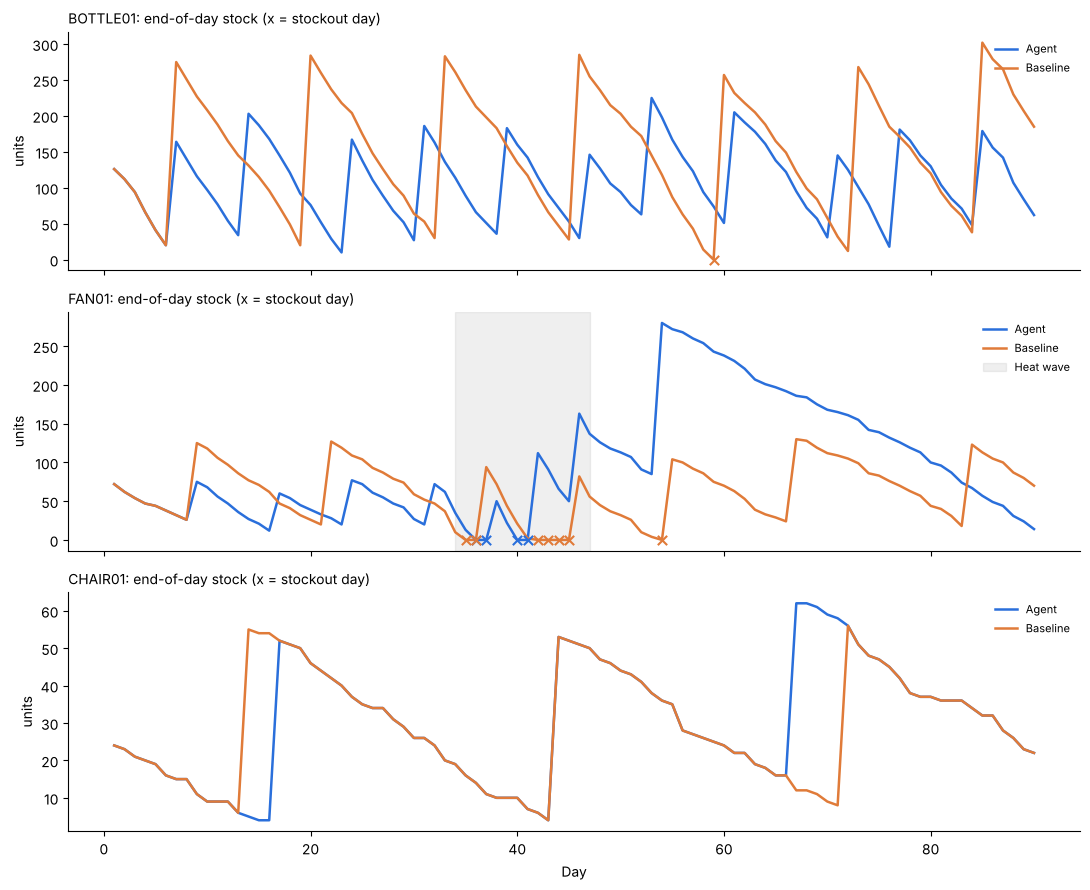

In [10]:
fig, axes = plt.subplots(len(SKUS), 1, figsize=(11, 9), sharex=True)
for ax, sku in zip(axes, SKUS):
    for log, label, color in [(agent_log, "Agent", "#2a6fdb"), (baseline_log, "Baseline", "#e07b39")]:
        s = log[log["sku"] == sku]
        ax.plot(s["day"], s["end_stock"], label=label, color=color, linewidth=1.8)
        lost = s[s["unmet"] > 0]
        ax.scatter(lost["day"], [0] * len(lost), color=color, marker="x", s=45, zorder=3)
    if sku == "FAN01":
        ax.axvspan(34, 47, color="grey", alpha=0.12, label="Heat wave")
    ax.set_title(f"{sku}: end-of-day stock (x = stockout day)", loc="left", fontsize=10)
    ax.set_ylabel("units")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=8, loc="upper right")
axes[-1].set_xlabel("Day")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/inventory_chart.png", dpi=130)
plt.show()

## Step 9: Trade-off analysis: service level and alpha
We rerun the agent (all 3 SKUs, same data) for every combination of service level 90/95/99% and
alpha 0.1/0.3/0.5. Service level here replaces each SKU's value from `params.csv`.

In [11]:
tradeoff_rows = []
for service_level in [0.90, 0.95, 0.99]:
    for alpha in [0.1, 0.3, 0.5]:
        m = summarize(run_all("agent", alpha=alpha, service_level=service_level))
        tradeoff_rows.append({"service_level": f"{service_level:.0%}", "alpha": alpha,
                              "fill_rate": f"{m['Fill rate']:.1%}", "stockout_days": m["Stockout days"],
                              "unmet_units": m["Unmet demand (units)"],
                              "avg_stock_value": round(m["Avg $ in stock"]),
                              "holding_cost": round(m["Holding cost"], 2),
                              "stockout_cost": round(m["Stockout cost"], 2),
                              "total_cost": round(m["Total cost"], 2)})
tradeoff = pd.DataFrame(tradeoff_rows)
tradeoff.to_csv(f"{OUTPUT_DIR}/tradeoff.csv", index=False)
print(tradeoff.to_string(index=False))

service_level  alpha fill_rate  stockout_days  unmet_units  avg_stock_value  holding_cost  stockout_cost  total_cost
          90%    0.1     97.7%              6           69             5661       1397.15           1026     2423.15
          90%    0.3     98.3%              4           52             6550       1617.16            780     2397.16
          90%    0.5     97.7%              6           68             8151       2006.68            687     2693.68
          95%    0.1     97.9%              4           64             5830       1437.02            960     2397.02
          95%    0.3     98.4%              4           49             6724       1658.00            735     2393.00
          95%    0.5     98.2%              5           55             8360       2057.40            582     2639.40
          99%    0.1     98.1%              4           58             6118       1504.85            870     2374.85
          99%    0.3     98.6%              4           43      

Where the alpha differences come from: the same runs at the 95% service level, split by SKU.

In [12]:
alpha_rows = []
for alpha in [0.1, 0.3, 0.5]:
    log = run_all("agent", alpha=alpha, service_level=0.95)
    for sku in SKUS:
        s = log[log["sku"] == sku]
        alpha_rows.append({"alpha": alpha, "sku": sku, "unmet_units": int(s["unmet"].sum()),
                           "avg_stock": round(s["end_stock"].mean(), 1), "max_stock": int(s["end_stock"].max()),
                           "holding_cost": round(s["holding_cost"].sum(), 2)})
print(pd.DataFrame(alpha_rows).to_string(index=False))

 alpha      sku  unmet_units  avg_stock  max_stock  holding_cost
   0.1 BOTTLE01            0       97.6        207        263.43
   0.1    FAN01           64       80.5        250        579.84
   0.1  CHAIR01            0       26.4         53        593.75
   0.3 BOTTLE01            0      107.5        225        290.19
   0.3    FAN01           49       95.4        280        686.56
   0.3  CHAIR01            0       30.3         62        681.25
   0.5 BOTTLE01           27      117.9        277        318.33
   0.5    FAN01           28      134.2        337        966.32
   0.5  CHAIR01            0       34.3         71        772.75


## Step 10: Built-in checks
These prove the simulation follows the business rules. If any rule is broken, the cell stops with an error.

In [13]:
def check_log(log, name, alpha=ALPHA):
    for sku in SKUS:
        s = log[log["sku"] == sku].reset_index(drop=True)
        p = sku_params(sku)
        L, moq = int(p["lead_time_days"]), int(p["min_order_qty"])
        orders = s[s["order_qty"] > 0]

        # One logged action with a reason for every day
        assert len(s) == len(demand) and s["day"].tolist() == list(range(1, len(demand) + 1))
        assert s["action"].isin(["ORDER", "WAIT"]).all() and (s["reason"].str.len() > 0).all()

        # Lead time: every order arrives exactly lead_time days later, in full, and not before
        assert ((orders["arrival_day"] - orders["day"]) == L).all()
        expected = orders[orders["arrival_day"] <= len(s)].groupby("arrival_day")["order_qty"].sum()
        actual = s[s["received"] > 0].set_index("day")["received"]
        assert expected.to_dict() == actual.to_dict(), f"{name} {sku}: receipts don't match orders"

        # MOQ: every order meets the supplier minimum
        assert (orders["order_qty"] >= moq).all()

        # Inventory balance every day: yesterday's close + received = today's open; open - supplied = close
        prev_close = [opening_stock[sku]] + s["end_stock"].tolist()[:-1]
        assert (s["start_stock"] == pd.Series(prev_close) + s["received"]).all()
        assert (s["end_stock"] == s["start_stock"] - s["supplied"]).all()
        assert (s["end_stock"] >= 0).all() and (s["supplied"] + s["unmet"] == s["demand"]).all()
        assert opening_stock[sku] + s["received"].sum() - s["supplied"].sum() == s["end_stock"].iloc[-1]

        # Costs match the definitions
        assert np.allclose(s["holding_cost"], s["end_stock"] * p["holding_cost_per_day"])
        assert np.allclose(s["stockout_cost"], s["unmet"] * p["stockout_cost"])

        if name == "agent":
            # Forecast only uses past sales: rebuild it independently with pandas' EWMA
            past_sales = pd.Series([INITIAL_FORECAST[sku]] + s["demand"].tolist()[:-1])
            rebuilt = past_sales.ewm(alpha=alpha, adjust=False).mean()
            assert np.allclose(s["forecast"], rebuilt, atol=0.01)
            # Inventory cap: position after ordering stays under the cap unless the log flags an override
            after = s["start_stock"] + s["on_order"] + s["order_qty"]
            over = (s["order_qty"] > 0) & (after > s["cap"] + 1)
            assert s.loc[over, "reason"].str.contains("CAP OVERRIDE").all()
        print(f"{name} {sku}: all checks passed ({len(orders)} orders, "
              f"{int((s['reason'].str.contains('CAP OVERRIDE')).sum())} cap overrides)")


check_log(agent_log, "agent")
check_log(baseline_log, "baseline")

agent BOTTLE01: all checks passed (12 orders, 0 cap overrides)
agent FAN01: all checks passed (9 orders, 0 cap overrides)
agent CHAIR01: all checks passed (4 orders, 2 cap overrides)
baseline BOTTLE01: all checks passed (7 orders, 0 cap overrides)
baseline FAN01: all checks passed (7 orders, 0 cap overrides)
baseline CHAIR01: all checks passed (3 orders, 0 cap overrides)


**Data validation check:** feed `load_and_validate` a deliberately broken copy of `sales.csv`
(a negative sale, a duplicate row, a missing date) and confirm it catches and fixes each one.

In [14]:
import tempfile

with tempfile.TemporaryDirectory() as tmp:
    broken = pd.read_csv(f"{DATA_DIR}/sales.csv")
    broken.loc[0, "qty_sold"] = -5                                  # negative sale
    broken = pd.concat([broken, broken.iloc[[1]]])                  # duplicate row
    broken = broken[broken["date"] != "2026-07-10"]                 # a missing date (all SKUs)
    broken.to_csv(f"{tmp}/sales.csv", index=False)
    test_demand, _, _ = load_and_validate(f"{tmp}/sales.csv")
    assert test_demand.loc["2026-07-01", broken.iloc[0]["sku"]] == 0           # negative -> 0
    assert test_demand.loc["2026-07-10"].sum() == 0                            # missing date -> 0
    assert len(test_demand) == len(demand)                                     # calendar still complete
print("Data validation check passed")

Note: 1 duplicate date/SKU rows were added together
Note: BOTTLE01 has 1 dates with no sales row, treated as zero demand
Note: CHAIR01 has 16 dates with no sales row, treated as zero demand
Note: FAN01 has 1 dates with no sales row, treated as zero demand
Data validation check passed


## Reflection: inventory vs service
*(All numbers below come from the runs above. Rerun after changing settings and they will move.)*

**Agent vs baseline.** Across the 3 SKUs the agent cut total cost from $3,241.36 to $2,393.00 and raised fill
rate from 96.0% to 98.4%. It held fewer units on average (233.1 vs 241.4) but tied up more money in them
($6,724.01 vs $6,150.30), mostly expensive fans left over after the heat wave. It didn't win everywhere:
- **BOTTLE01 (steady):** the agent held less stock on average (107.5 vs 149.8 units) and still never ran out,
  because it placed smaller orders more often (12 vs 7 POs). That only works because orders cost $0 here.
  With a real fixed cost per PO, ordering that often would cost more.
- **FAN01 (heat wave):** the heat wave is a jump in demand, not noise, so safety stock can't absorb it. With a 7-day
  lead time, the first order placed after demand jumps lands a week later. The agent still lost far fewer fans
  (49 vs 113 units) because its forecast caught up within days. It paid for that afterward: its forecast was
  still 22.6/day when the wave ended, so the 204-unit order placed on day 47 left it holding up to 280 fans,
  and its FAN01 holding cost was $686.56 vs $449.68.
- **CHAIR01 (slow mover):** an MOQ of 50 is about a month of demand, so both policies behave almost the same.
  The agent's cost was slightly higher ($681.25 vs $656.25) because sales ran above the planner's 1.5/day guess,
  its forecast rose, and it reordered a bit earlier on the third cycle. The cap made it wait on 5 days and it
  overrode the cap twice when waiting would have risked a stockout. Both overrides are flagged in the log.

**Service level.** At alpha 0.3, moving from 90% to 99% raised the average money tied up in stock from $6,550 to
$7,046 and cut lost units from 52 to 43, while total cost barely moved ($2,397.16 to $2,378.86). Here a lost sale
costs 160 to 200 times what it costs to hold one unit for a day, so extra buffer roughly pays for itself. If stockouts were
cheaper or holding were pricier, the higher service level would start costing more than it saves.

**Alpha.** 0.5 was the most expensive setting at every service level. A forecast that jumps with every busy or slow
day under-ordered BOTTLE01 after slow stretches (27 units lost vs 0 at alpha 0.3) and over-ordered FAN01 at the
peak of the heat wave (holding $966.32 vs $686.56). Alpha 0.1 kept the least stock but reacted slowly to the heat
wave (64 fans lost). 0.3 balanced the two.

**Bottom line:** more inventory buys service, but the price depends on the SKU. For cheap, steady items it's
nearly free. For a seasonal item, the risk moves from running out during the spike to being stuck with stock
after it. A forecast alone can't see a heat wave coming, so in practice a person (or a weather or promo signal)
should be able to tell the agent about known events ahead of time.